# Model zero and positive continuous responses

A compound Poisson–Gamma response can be exactly zero or positive and continuous. This simulation sums a Poisson number of Gamma events, matching a Tweedie model with power 1.5 rather than replacing zeros with small positive values.

The mean–variance relation is $\operatorname{Var}(Y\mid x)=\phi\mu(x)^p$. Here $p=1.5$ is fixed, so increasing the mean increases variance faster than proportionally but slower than quadratically.

## Generate and fit the response

The split is fixed before fitting. Smoothing is selected on the training rows; the test outcomes are used only for final assessment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng=np.random.default_rng(108)
data=pd.DataFrame({"x":rng.uniform(0,1,700)})
grid=pd.DataFrame({"x":np.linspace(0,1,180)})
mu=np.exp(.4+.8*np.sin(2*np.pi*data.x))
phi=.8
rate=2*np.sqrt(mu)/phi
events=rng.poisson(rate)
data["y"]=np.array([rng.gamma(shape=int(n),scale=phi*.5*np.sqrt(m)) if n else 0. for n,m in zip(events,mu)])
train,test=train_test_split(data,test_size=.25,random_state=108)
true_grid=np.exp(.4+.8*np.sin(2*np.pi*grid.x))
pd.DataFrame({"Split":["Training","Test"],"Zero fraction":[float((train.y==0).mean()),float((test.y==0).mean())]}).style.hide(axis="index").format({"Zero fraction":"{:.1%}"})

Split,Zero fraction
Training,5.9%
Test,5.1%


## Select smoothness with EFS

The joint Newton and BFGS routes fail their convergence checks for this example. We use the supported extended Fellner–Schall (EFS) route for REML smoothing selection; it updates dispersion inside the fitting iterations while keeping the supplied power at 1.5. The optimizer trace and coefficient-fit result must both report convergence before we assess the fit. A converged EFS update is not a guarantee of a global optimum.

In [2]:
from nampy.gam.diagnostics import build_optimizer_trace

model = GAM(
    formula="y ~ s(x, bs='cr', k=12)",
    family={"name": "tw", "theta": 1.5},
    optimize_smoothing=True,
    smoothing_method="reml",
    smoothing_optimizer="efs",
).fit(train)
convergence = build_optimizer_trace(model)["fit"]


## Inspect the mean and remaining variation

The mean curve describes expected responses rather than individual outcomes. The residual panel checks variation relative to the fitted family; held-out errors below use the response scale.

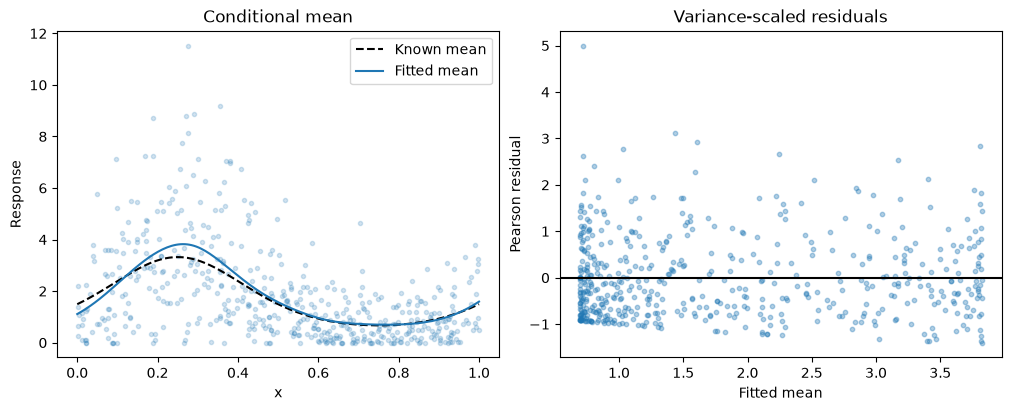

Test RMSE,Test MAE
1.453,1.094


In [3]:
figure,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
axes[0].scatter(train.x,train.y,s=9,alpha=.2)
axes[0].plot(grid.x,true_grid,"k--",label="Known mean")
axes[0].plot(grid.x,model.predict(grid,type="response"),label="Fitted mean")
axes[0].set(xlabel="x",ylabel="Response",title="Conditional mean")
axes[0].legend()
axes[1].scatter(model.predict(train,type="response"),model.residuals(type="pearson"),s=10,alpha=.35)
axes[1].axhline(0,color="black")
axes[1].set(xlabel="Fitted mean",ylabel="Pearson residual",title="Variance-scaled residuals")
plt.show()
plt.close(figure)
prediction=model.predict(test,type="response")
pd.DataFrame({"Test RMSE":[mean_squared_error(test.y,prediction)**.5],"Test MAE":[np.mean(np.abs(test.y-prediction))]}).style.hide(axis="index").format("{:.3f}")

The power parameter is supplied as 1.5 in this example. The fitted mean is not the probability of zero; the table shows the empirical zero fractions separately.

With EFS, test RMSE is 1.453 and MAE is 1.094 on the response scale. The fitted mean follows the known curve, while the residual panel assesses remaining variation relative to the Tweedie variance. These errors concern individual outcomes, not just recovery of the noiseless mean.